In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv('informacion_campana_bancaria_2026.csv')
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,single,basic.9y,no,yes,no,telephone,jun,mon,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.958,5228.1,yes
1,58,retired,married,professional.course,no,yes,no,cellular,aug,mon,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.970,5228.1,no
2,48,technician,married,professional.course,no,yes,yes,cellular,nov,fri,...,3,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,no
3,39,blue-collar,single,basic.9y,no,yes,no,cellular,apr,thu,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.483,5099.1,no
4,56,services,married,basic.4y,NaN,no,no,telephone,jun,mon,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.865,5228.1,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41383,21,unemployed,married,high.school,no,yes,yes,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
41384,24,blue-collar,single,basic.9y,no,yes,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,no
41385,21,student,single,basic.4y,no,no,no,cellular,mar,mon,...,2,999,0,nonexistent,-1.8,92.843,-50.0,1.520,5099.1,no
41386,52,admin.,married,high.school,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,no


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41388 entries, 0 to 41387
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41388 non-null  int64  
 1   job             41054 non-null  object 
 2   marital         41307 non-null  object 
 3   education       39644 non-null  object 
 4   default         32743 non-null  object 
 5   housing         40392 non-null  object 
 6   loan            40392 non-null  object 
 7   contact         41388 non-null  object 
 8   month           41388 non-null  object 
 9   day_of_week     41388 non-null  object 
 10  duration        41388 non-null  int64  
 11  campaign        41388 non-null  int64  
 12  pdays           41388 non-null  int64  
 13  previous        41388 non-null  int64  
 14  poutcome        41388 non-null  object 
 15  emp.var.rate    41388 non-null  float64
 16  cons.price.idx  41388 non-null  float64
 17  cons.conf.idx   41388 non-null 

In [4]:
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000,41388.000000
mean,40.026095,257.036895,2.569706,962.507635,0.172804,0.081997,93.575708,-40.501957,3.621407,5167.037733
std,10.422178,259.271449,2.775227,186.832646,0.494591,1.570952,0.578922,4.629124,1.734390,72.244581
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,101.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.000000,179.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,318.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


<Axes: >

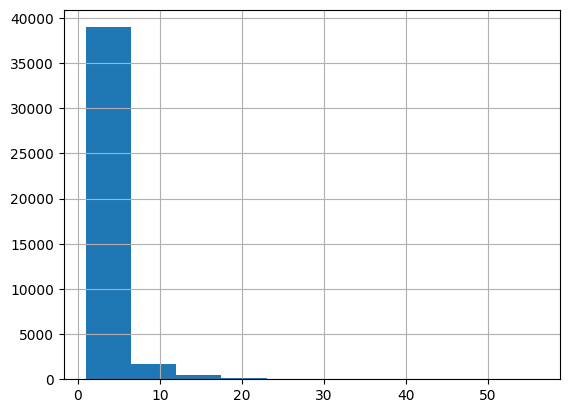

In [5]:
data['campaign'].hist()

##Limpieza de datos

In [6]:
#Se detectan la cantidad de registros duplicados
duplicados = data.duplicated().sum()
duplicados

np.int64(12)

In [7]:
#Se eliminan duplicados
data = data.drop_duplicates().copy()
data.duplicated().sum()

np.int64(0)

In [8]:
#Estandarizar. Convertir celdas totalmente vacías o con espacios en blancos reales (NaN)
data.replace(r'^\s*$', np.nan, regex=True, inplace=True)
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,single,basic.9y,no,yes,no,telephone,jun,mon,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.958,5228.1,yes
1,58,retired,married,professional.course,no,yes,no,cellular,aug,mon,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.970,5228.1,no
2,48,technician,married,professional.course,no,yes,yes,cellular,nov,fri,...,3,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,no
3,39,blue-collar,single,basic.9y,no,yes,no,cellular,apr,thu,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.483,5099.1,no
4,56,services,married,basic.4y,NaN,no,no,telephone,jun,mon,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.865,5228.1,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41383,21,unemployed,married,high.school,no,yes,yes,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
41384,24,blue-collar,single,basic.9y,no,yes,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,no
41385,21,student,single,basic.4y,no,no,no,cellular,mar,mon,...,2,999,0,nonexistent,-1.8,92.843,-50.0,1.520,5099.1,no
41386,52,admin.,married,high.school,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,no


In [9]:
#Verificar la cantidad de Nulos
data.isnull().sum()

,0
age,0
job,334
marital,81
education,1743
default,8644
housing,996
loan,996
contact,0
month,0
day_of_week,0


In [10]:
data['job'].value_counts(dropna=False)

,count
job,
admin.,10483
blue-collar,9294
technician,6776
services,3979
management,2933
retired,1726
entrepreneur,1463
self-employed,1427
housemaid,1065


In [11]:
#Limpieza job mayores de 65 (imputación)
data.loc[(data['job'].isnull()) & (data['age'] >= 65), 'job'] = 'retired'
data['job'].value_counts(dropna=False)

,count
job,
admin.,10483
blue-collar,9294
technician,6776
services,3979
management,2933
retired,1737
entrepreneur,1463
self-employed,1427
housemaid,1065


In [12]:
filt=data.groupby([data['age']<=24])['job'].value_counts(dropna=False)
filt

age    job          
False  admin.           10325
       blue-collar       9100
       technician        6672
       services          3822
       management        2906
       retired           1736
       entrepreneur      1451
       self-employed     1415
       housemaid         1060
       unemployed        1000
       student            499
       NaN                317
True   student            379
       blue-collar        194
       admin.             158
       services           157
       technician         104
       management          27
       unemployed          18
       entrepreneur        12
       self-employed       12
       NaN                  6
       housemaid            5
       retired              1
Name: count, dtype: int64

In [13]:
#Limpieza job menores o iguales de 24 (imputación)
data.loc[(data['job'].isnull()) & (data['age'] <= 24), 'job'] = 'student'
data['job'].value_counts(dropna=False)

,count
job,
admin.,10483
blue-collar,9294
technician,6776
services,3979
management,2933
retired,1737
entrepreneur,1463
self-employed,1427
housemaid,1065


In [14]:
#Nivel de educación información nula
data['education'].value_counts(dropna=False)

,count
education,
university.degree,12228
high.school,9555
basic.9y,6068
professional.course,5263
basic.4y,4203
basic.6y,2298
NaN,1743
illiterate,18


In [15]:
filt2=data.groupby('job')['education'].value_counts(dropna=False)
data[data['job']=='management']['education'].value_counts(dropna=False)

,count
education,
university.degree,2071
high.school,298
basic.9y,166
NaN,123
basic.4y,101
professional.course,89
basic.6y,85


In [16]:
#Imputar educación por moda condicional del job
data['education'] = data.groupby('job')['education'].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))
data['education'].value_counts(dropna=False)


,count
education,
university.degree,12668
high.school,9836
basic.9y,6495
professional.course,5465
basic.4y,4301
basic.6y,2276
NaN,317
illiterate,18


In [17]:
data[data['job']=='management']['education'].value_counts(dropna=False)

,count
education,
university.degree,2194
high.school,298
basic.9y,166
basic.4y,101
professional.course,89
basic.6y,85


In [18]:
# Filtramos SOLO a los clientes que sabemos que tienen hipoteca o préstamo
clientes_con_deuda = data[(data['housing'] == 'yes') | (data['loan'] == 'yes')]

# Le preguntamos a Pandas: De esta gente con deuda, ¿cómo está su default?
clientes_con_deuda['default'].value_counts(dropna=False)

,count
default,
no,19305
NaN,4936
yes,1


In [19]:
#Standarizamos los 'unknown'
cols_financieras = ['default', 'housing', 'loan']
# Usamos .loc para asegurar que modificamos el DataFrame original sin advertencias
data.loc[:, cols_financieras] = data.loc[:, cols_financieras].replace('unknown', np.nan)
data.loc[:, cols_financieras] = data.loc[:, cols_financieras].fillna('Desconocido')



In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41376 entries, 0 to 41387
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41376 non-null  int64  
 1   job             41059 non-null  object 
 2   marital         41295 non-null  object 
 3   education       41059 non-null  object 
 4   default         41376 non-null  object 
 5   housing         41376 non-null  object 
 6   loan            41376 non-null  object 
 7   contact         41376 non-null  object 
 8   month           41376 non-null  object 
 9   day_of_week     41376 non-null  object 
 10  duration        41376 non-null  int64  
 11  campaign        41376 non-null  int64  
 12  pdays           41376 non-null  int64  
 13  previous        41376 non-null  int64  
 14  poutcome        41376 non-null  object 
 15  emp.var.rate    41376 non-null  float64
 16  cons.price.idx  41376 non-null  float64
 17  cons.conf.idx   41376 non-null  floa

##Tratamiento de datos y Transformación




In [21]:
#Al analizar el default, housing y loan por separado nos hace perder
#visión del panorama completo. Alguien con default o lleno de préstamos
#no tiene liquidez para comprar un depósito a plazo (póliza).
#Tratamiento: Vamos a crear una nueva súper-variable que clasifique el estrés financiero del cliente.
def calcular_estres_financiero(row):
    # Regla 1: Si está en default, su capacidad es NULA
    if row['default'] == 'yes':
        return 'Sin_Liquidez (Moroso)'

    # Regla 2: Si tiene Hipoteca Y Préstamo personal, está ahogado en deudas
    elif row['housing'] == 'yes' and row['loan'] == 'yes':
        return 'Alta_Deuda (Poca Liquidez)'

    # Regla 3: Si tiene uno de los dos
    elif row['housing'] == 'yes' or row['loan'] == 'yes':
        return 'Deuda_Moderada'

    # Regla 4: No tiene deudas, es el cliente ideal para invertir
    elif row['housing'] == 'no' and row['loan'] == 'no':
        return 'Alta_Liquidez (Sin Deudas)'

    # Regla 5: Los que ocultaron información (El 20% que descubrimos)
    else:
        return 'Perfil_Desconocido'

# Aplicar la función a cada fila para crear la nueva columna usando .loc de forma segura
data.loc[:, 'perfil_liquidez'] = data.apply(calcular_estres_financiero, axis=1)
data['perfil_liquidez'].value_counts()

,count
perfil_liquidez,
Deuda_Moderada,20534
Alta_Liquidez (Sin Deudas),16136
Alta_Deuda (Poca Liquidez),3707
Perfil_Desconocido,996
Sin_Liquidez (Moroso),3


In [22]:
#OBSERVACION 1: COL SI FUE CONTACTADO O NO ANTERIORMENTE
#Estandarizar los pday=999, para que pueda luego hacer calculos de media, mediana.
# Crear columna bandera: ¿Es un cliente nuevo en base a pdays? (1=Sí, 0=No)
data['es_cliente_nuevo'] = (data['pdays'] == 999).astype(int)

# Reemplazar el 999 por NaN para no romper los promedios ni distorsionar
# el peso de los días
data['pdays'] = data['pdays'].replace(999, np.nan)

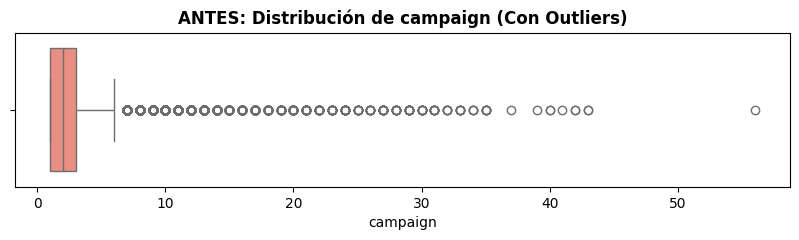

In [23]:
#Tratamiento de outliers
#Boxplot ANTES
plt.figure(figsize=(10, 2))
sns.boxplot(x=data['campaign'], color='salmon')
plt.title(f'ANTES: Distribución de campaign (Con Outliers)', fontweight='bold')
plt.show()

In [24]:
#Funcion quitar outliers
def tratar_outliers_iqr(df_in, col_name):
    print(f"\n{'='*50}")
    print(f"🛠️ ANALIZANDO OUTLIERS EN: {col_name.upper()}")
    print(f"{'='*50}")

    # 1. Boxplot ANTES
    plt.figure(figsize=(10, 2))
    sns.boxplot(x=df_in[col_name], color='salmon')
    plt.title(f'ANTES: Distribución de {col_name} (Con Outliers)', fontweight='bold')
    plt.show()

    # 2. Cálculo Matemático (Q1, Q3, IQR)
    Q1 = df_in[col_name].quantile(0.25)
    Q3 = df_in[col_name].quantile(0.75)
    IQR = Q3 - Q1

    # 3. Definir Límites (Fórmula de Tukey)
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f"📊 Estadísticas calculadas:")
    print(f"   - Q1 (25%): {Q1}")
    print(f"   - Q3 (75%): {Q3}")
    print(f"   - IQR (Q3-Q1): {IQR}")
    print(f"   - Límite Inferior: {limite_inferior}")
    print(f"   - Límite Superior: {limite_superior}")

    # 4. Detectar cuántos outliers hay
    outliers = df_in[(df_in[col_name] < limite_inferior) | (df_in[col_name] > limite_superior)]
    print(f"\n🚨 Se detectaron {len(outliers)} outliers en '{col_name}'.")

    # 5. Filtrar el DataFrame (Eliminar Outliers)
    df_out = df_in[(df_in[col_name] >= limite_inferior) & (df_in[col_name] <= limite_superior)].copy()

    # 6. Boxplot DESPUÉS
    plt.figure(figsize=(10, 2))
    sns.boxplot(x=df_out[col_name], color='lightgreen')
    plt.title(f'DESPUÉS: Distribución de {col_name} (Sin Outliers)', fontweight='bold')
    plt.show()

    print(f"✅ Filas originales: {len(df_in)} | Filas tras limpieza: {len(df_out)}")
    return df_out



🛠️ ANALIZANDO OUTLIERS EN: CAMPAIGN


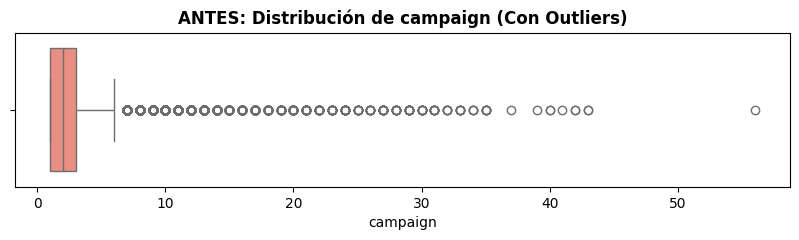

📊 Estadísticas calculadas:
   - Q1 (25%): 1.0
   - Q3 (75%): 3.0
   - IQR (Q3-Q1): 2.0
   - Límite Inferior: -2.0
   - Límite Superior: 6.0

🚨 Se detectaron 2424 outliers en 'campaign'.


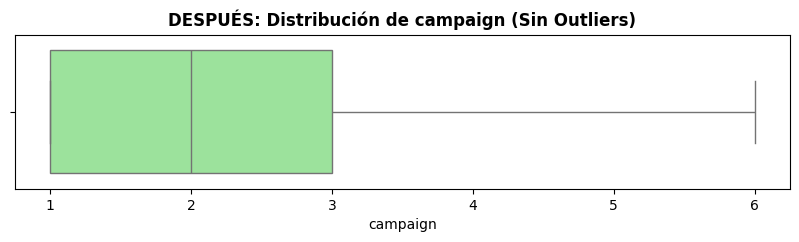

✅ Filas originales: 41376 | Filas tras limpieza: 38952

🛠️ ANALIZANDO OUTLIERS EN: AGE


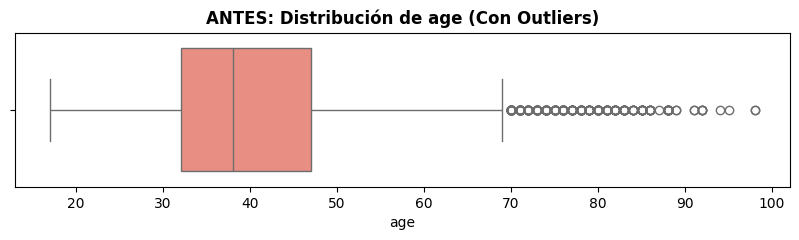

📊 Estadísticas calculadas:
   - Q1 (25%): 32.0
   - Q3 (75%): 47.0
   - IQR (Q3-Q1): 15.0
   - Límite Inferior: 9.5
   - Límite Superior: 69.5

🚨 Se detectaron 458 outliers en 'age'.


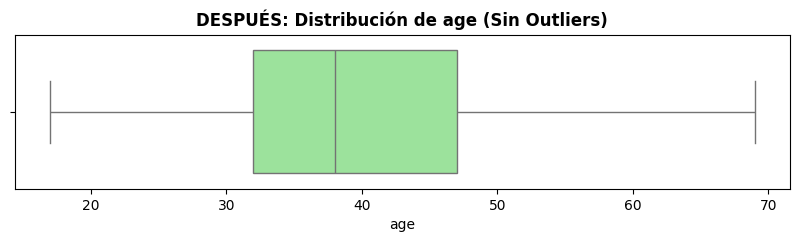

✅ Filas originales: 38952 | Filas tras limpieza: 38494


In [25]:
# ---------------------------------------------------------
# APLICANDO LA FUNCIÓN A NUESTRAS VARIABLES CLAVE
# ---------------------------------------------------------

# A. Limpiar el acoso telefónico (campaign)
data_trat_outliers = tratar_outliers_iqr(data, 'campaign')

# B. Limpiar las edades extremas (age)
data_trat_outliers = tratar_outliers_iqr(data_trat_outliers, 'age')

# C. Limpiar la duración (duration)
#data_trat_outliers = tratar_outliers_iqr(data_trat_outliers, 'duration')



In [26]:
data_trat_outliers[['age','duration','campaign','previous']].describe()

,age,duration,campaign,previous
count,38494.000000,38494.000000,38494.000000,38494.000000
mean,39.579181,261.150881,2.048293,0.174495
std,9.677761,259.743355,1.282193,0.493243
min,17.000000,0.000000,1.000000,0.000000
25%,32.000000,105.000000,1.000000,0.000000
50%,38.000000,182.000000,2.000000,0.000000
75%,47.000000,322.000000,3.000000,0.000000
max,69.000000,4918.000000,6.000000,7.000000


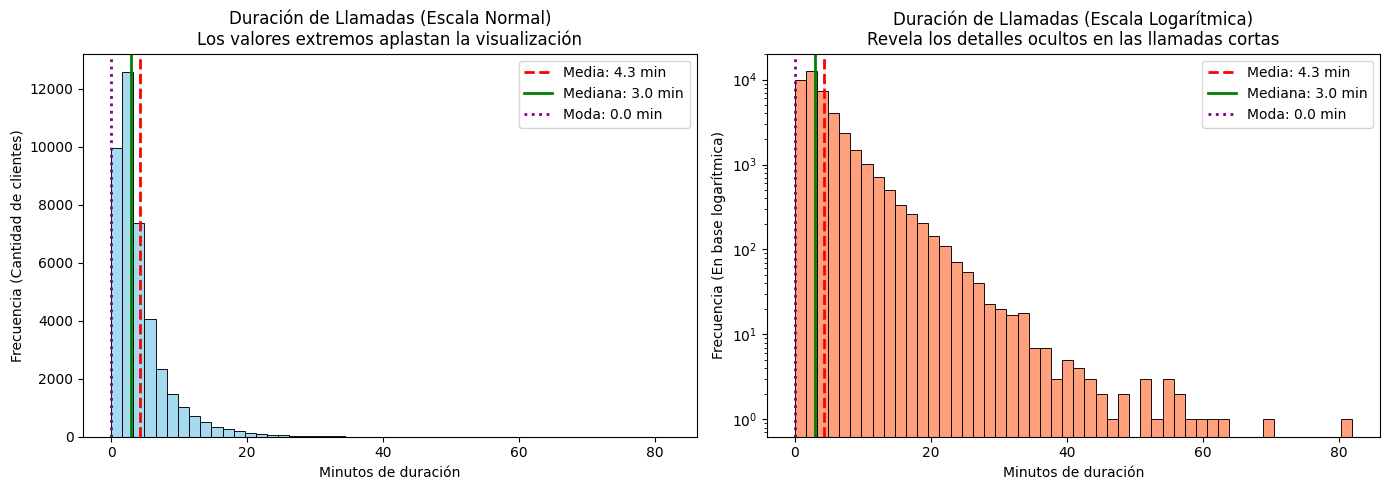

In [27]:
# Crear la variable de duración en minutos (sin elimnar ouliers en la duración de las llamadas)
data['duration_min_o'] = data['duration'] / 60

# Calcular métricas estadísticas de la duración
media = data['duration_min_o'].mean()
mediana = data['duration_min_o'].median()
moda = data['duration_min_o'].mode()[0]

plt.figure(figsize=(14, 5))

# Gráfico 1: Escala Lineal Normal (El problema del aplastamiento)
plt.subplot(1, 2, 1)
sns.histplot(data=data, x='duration_min_o', bins=50, color='skyblue', edgecolor='black')

# Añadiendo líneas de tendencia central
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Media: {media:.1f} min')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.1f} min')
plt.axvline(moda, color='purple', linestyle=':', linewidth=2, label=f'Moda: {moda:.1f} min')

plt.title('Duración de Llamadas (Escala Normal)\nLos valores extremos aplastan la visualización', fontsize=12)
plt.xlabel('Minutos de duración')
plt.ylabel('Frecuencia (Cantidad de clientes)')
plt.legend()

# Gráfico 2: Escala Logarítmica (La magia analítica)
plt.subplot(1, 2, 2)
sns.histplot(data=data, x='duration_min_o', bins=50, color='coral', edgecolor='black')
plt.yscale('log')

# Añadiendo líneas de tendencia central (se comportan igual, pero el eje Y cambia)
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Media: {media:.1f} min')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.1f} min')
plt.axvline(moda, color='purple', linestyle=':', linewidth=2, label=f'Moda: {moda:.1f} min')

plt.title('Duración de Llamadas (Escala Logarítmica)\nRevela los detalles ocultos en las llamadas cortas', fontsize=12)
plt.xlabel('Minutos de duración')
plt.ylabel('Frecuencia (En base logarítmica)')
plt.legend()

plt.tight_layout()
plt.show()



**Interpretación del Negocio:** En el gráfico logarítmico (derecha), ya no se ve una sola barra gigante pegada al cero. Empezamos a notar claramente los "escalones" en los primeros 5 minutos críticos, permitiéndote analizar exactamente en qué minuto las personas tienden a cortar la llamada con mayor frecuencia, sin que las llamadas raras de 80 minutos arruinen la perspectiva. Observar la separación entre la Moda (rojo), Mediana (verde) y Media (roja) es la demostración gráfica definitiva de que los datos tienen una "cola larga" a la derecha.

In [28]:
# Crear la variable de duración en minutos
data_trat_outliers['duration_min'] = data_trat_outliers['duration'] / 60

# Convertir 'y' a numérico para poder calcular tasas de conversión (promedios)
data_trat_outliers['tasa_exito'] = data_trat_outliers['y'].map({'yes': 1, 'no': 0})

# Feature Transformation: Crear Rangos de Edad para análisis categórico
data_trat_outliers['rango_edad'] = pd.cut(data_trat_outliers['age'],
                          bins=[17, 30, 45, 60, 100],
                          labels=['Jóvenes (18-30)', 'Adultos (31-45)', 'Maduros (46-60)', 'Tercera Edad (60+)'])


In [29]:
# Feature Transformation 2: Crear Rangos del Euribor usando Cuantiles (qcut)
# Dividimos la tasa de interés en 3 grupos balanceados: Bajo, Medio, Alto
data_trat_outliers['nivel_euribor'] = pd.qcut(data_trat_outliers['euribor3m'], q=3, labels=['Bajo', 'Medio', 'Alto'])

##Analisis correlacional

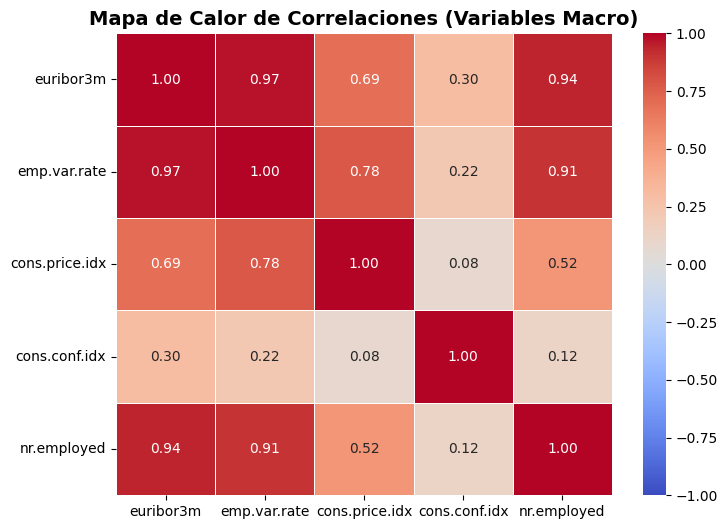

In [30]:
cols_macro = ['euribor3m', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'nr.employed' ]
matriz_macro_corr=data_trat_outliers[cols_macro].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_macro_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones (Variables Macro)', fontsize=14, fontweight='bold')
plt.show()


Esto significa que durante todo el tiempo que duró esta campaña bancaria, el país entero estuvo hundido en un pesimismo extremo, sin importar si ese mes el Euribor subía o bajaba un poquito. Posible crisis

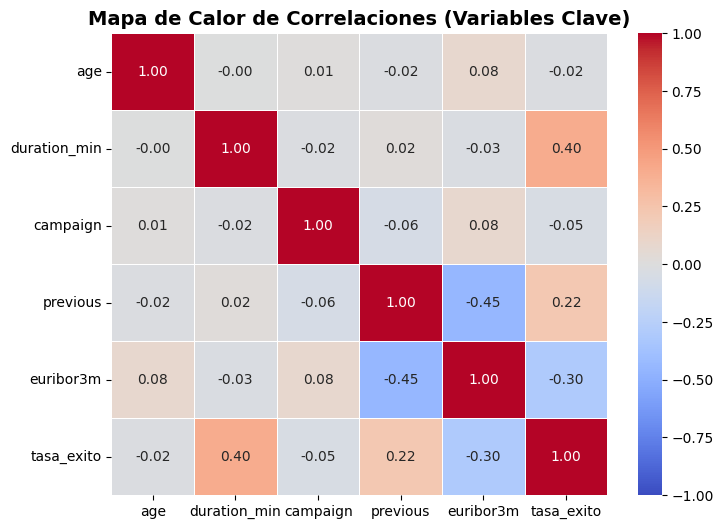

In [31]:
#Antes de hacer preguntas específicas, calculamos la matriz de correlación para ver qué
#variables numéricas se mueven en la misma dirección (positiva), en direcciones opuestas (negativa)
#o son completamente independientes (cercanas a 0).
# Seleccionar solo variables numéricas relevantes para la correlación
cols_numericas = ['age', 'duration_min', 'campaign', 'previous','euribor3m', 'tasa_exito']

# Calcular la matriz de correlación (método Pearson)
matriz_corr = data_trat_outliers[cols_numericas].corr()

# Visualizar la matriz con un Mapa de Calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones (Variables Clave)', fontsize=14, fontweight='bold')
plt.show()

**Interpretación y Argumentos Lógicos de la Correlación:**

**Correlación Positiva Moderada (+0.40 aprox.):** duration_min y tasa_exito

Explicación Lógica: A mayor tiempo de conversación, mayor probabilidad de que el cliente acepte la campaña. Un cliente que está interesado hace preguntas sobre la tasa de interés y los plazos, alargando la llamada. Un cliente que no quiere comprar, cuelga en el primer minuto.

**Correlación Negativa (-0.30 aprox.):** euribor3m y tasa_exito

Explicación Lógica: Cuando el indicador económico Euribor baja (correlación negativa), la tasa de éxito sube.

El Insight del "Factor Miedo": Aunque financieramente parece contradictorio (tasas bajas = menos ganancia), esto ocurrió durante la crisis financiera de 2008. Cuando el Euribor baja drásticamente, suele ser por una recesión. Los clientes, aterrorizados por la volatilidad de la bolsa o quiebras de empresas, prefieren un depósito a plazo fijo con bajo rendimiento pero capital garantizado. Es el efecto "Vuelo a la Calidad" o Refugio Seguro: prefieren ganar poco antes que arriesgarse a perderlo todo fuera del banco.

**Correlación Inexistente (~0.00):** age y campaign

Explicación Lógica: La correlación es nula. Esto nos indica que el banco (o su algoritmo de marcado automático) no discrimina por edad a la hora de insistir. Se llama la misma cantidad de veces a un joven de 20 años que a un jubilado de 70.

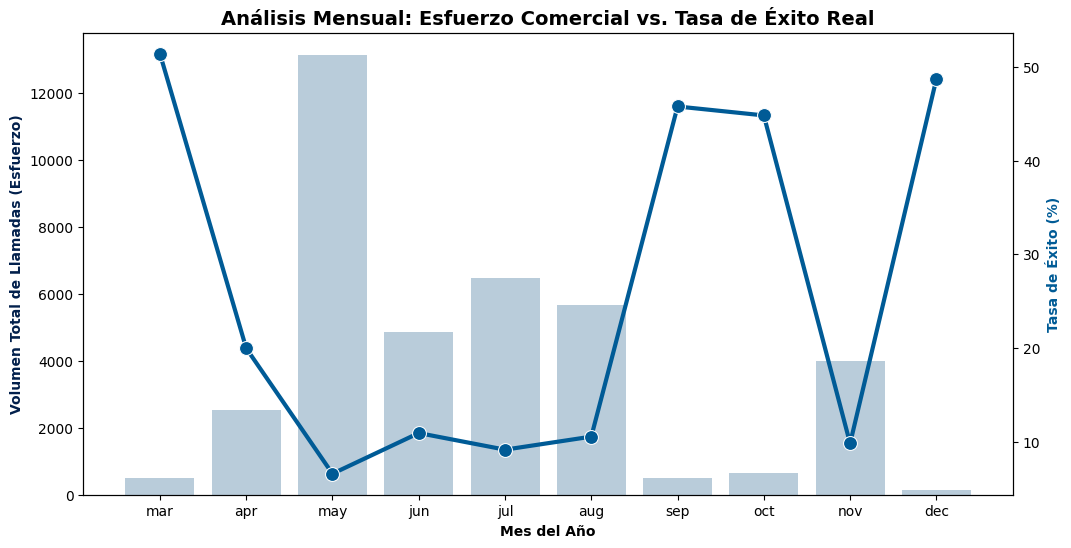

       volumen_llamadas  total_exitos  tasa_exito_pct
month                                                
mar                 490           252       51.428571
dec                 156            76       48.717949
sep                 511           234       45.792564
oct                 649           291       44.838213
apr                2539           507       19.968492
jun                4849           529       10.909466
aug                5663           596       10.524457
nov                4010           393        9.800499
jul                6481           592        9.134393
may               13146           863        6.564735


In [32]:
#Analisis meses
# 1. Definir el orden correcto de los meses (el dataset no tiene enero ni febrero)
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

# 2. Agrupar los datos calculando Volumen y Tasa de Éxito
analisis_mes = data_trat_outliers.groupby('month').agg(
    volumen_llamadas=('y', 'count'),
    total_exitos=('y', lambda x: (x == 'yes').sum())
).reindex(orden_meses)

# 3. Calcular la tasa de conversión porcentual
analisis_mes['tasa_exito_pct'] = (analisis_mes['total_exitos'] / analisis_mes['volumen_llamadas']) * 100

# 4. VISUALIZACIÓN DE DOBLE EJE (Volumen vs. Éxito)
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje Y Izquierdo (Barras para el Volumen de Llamadas)
color_volumen = '#b3cde0'
sns.barplot(x=analisis_mes.index, y='volumen_llamadas', data=analisis_mes, ax=ax1, color=color_volumen)
ax1.set_ylabel('Volumen Total de Llamadas (Esfuerzo)', color='#011f4b', fontweight='bold')
ax1.set_xlabel('Mes del Año', fontweight='bold')

# Eje Y Derecho (Línea para la Tasa de Éxito)
ax2 = ax1.twinx()
color_exito = '#005b96'
sns.lineplot(x=analisis_mes.index, y='tasa_exito_pct', data=analisis_mes, ax=ax2, color=color_exito, marker='o', linewidth=3, markersize=10)
ax2.set_ylabel('Tasa de Éxito (%)', color=color_exito, fontweight='bold')

plt.title('Análisis Mensual: Esfuerzo Comercial vs. Tasa de Éxito Real', fontsize=14, fontweight='bold')
plt.show()

# Mostrar la tabla de resultados para el informe
print(analisis_mes.sort_values(by='tasa_exito_pct', ascending=False))


**Interpretación de Negocio (Insights)**

**La Trampa de Mayo (may):** La barra de mayo es gigantesca (el mes con la frecuencia absoluta más alta de llamadas). Sin embargo, ¡la línea de tasa de éxito se desploma a su punto más bajo (aprox. 10%)! El banco gastó dinero en horas de Call Center para obtener pésimos resultados.

**Los mejores meses (mar, sep, oct, dec):** Tienen barras de volumen muy bajitas, pero la línea de éxito se dispara (llegando a tasas del 40-50%).

**Marzo/Septiembre:** Suelen coincidir con cierres de trimestres fiscales o retornos de vacaciones donde los clientes reorganizan sus finanzas.

**Diciembre:** El innegable "Efecto Aguinaldo/Bono". Los clientes tienen liquidez excedente.

/tmp/ipykernel_201/519805775.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=analisis_dia.index, y='tasa_exito_pct', data=analisis_dia, palette='viridis')


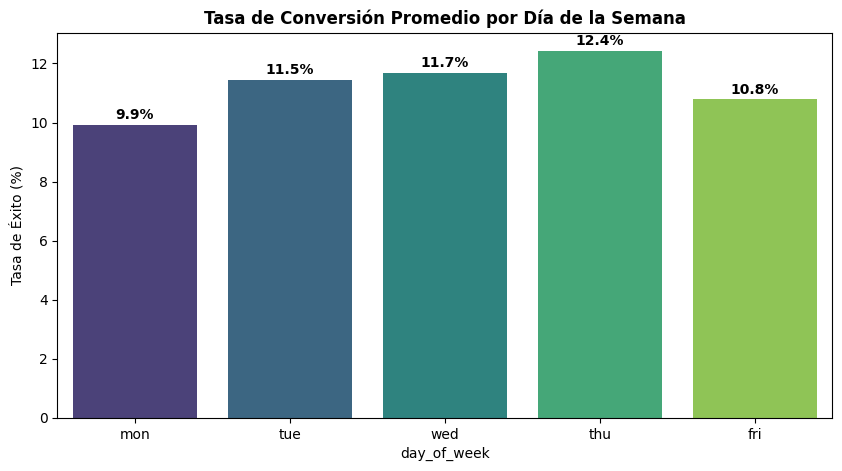

In [33]:
#Análisis por Día de la Semana:
#¿Importa el día en el que llamamos?
#A simple vista, el volumen se distribuye igual, pero la tolerancia del cliente cambia.
orden_dias = ['mon', 'tue', 'wed', 'thu', 'fri']

analisis_dia = data_trat_outliers.groupby('day_of_week').agg(
    volumen=('y', 'count'),
    tasa_exito_pct=('y', lambda x: (x == 'yes').mean() * 100)
).reindex(orden_dias)

plt.figure(figsize=(10, 5))
sns.barplot(x=analisis_dia.index, y='tasa_exito_pct', data=analisis_dia, palette='viridis')
plt.title('Tasa de Conversión Promedio por Día de la Semana', fontweight='bold')
plt.ylabel('Tasa de Éxito (%)')
for i, v in enumerate(analisis_dia['tasa_exito_pct']):
    plt.text(i, v + 0.2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.show()



**Interpretación de Negocio (Insights)**

**El "Valle" del Lunes (mon):** El inicio de semana presenta la tasa más baja de conversión (9.7%). Los clientes retoman su rutina laboral, suelen estar abrumados con tareas pendientes y reuniones, mostrando nula disposición para atender llamadas comerciales.

**Zona de estabilidad (tue, wed, thu):** La verdadera zona de estabilidad y mayor éxito se da entre el martes y el jueves. Vemos una tendencia ascendente que parte de 11.1% el martes y alcanza su punto máximo de la semana el jueves (11.8%). Este es el momento ideal para realizar los mayores esfuerzos de venta.

**La Caída del Viernes (fri):** El viernes muestra nuevamente un declive importante (cayendo al 10.4%). Los clientes ya están mentalmente desconectados, planeando su fin de semana, y son mucho menos propensos a escuchar ofertas o tomar decisiones financieras complejas.

**Análisis (Día x Mes)**

Combinar ambas métricas nos da el "Mapa de Calor" definitivo para asignar a nuestros vendedores.

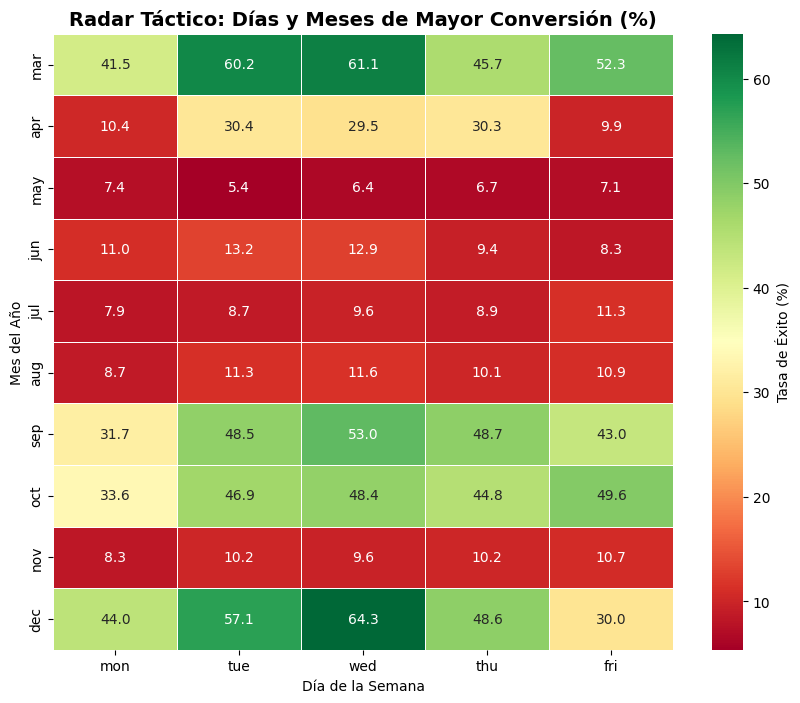

In [34]:
# Crear una tabla dinámica (pivot table) de Tasa de Éxito (%)
pivot_tiempo = pd.pivot_table(
    data_trat_outliers,
    values='tasa_exito', # Recuerda que mapeamos 'yes'=1, 'no'=0 previamente
    index='month',
    columns='day_of_week',
    aggfunc=lambda x: x.mean() * 100 # Multiplicado por 100 para ver porcentaje
).reindex(index=orden_meses, columns=orden_dias)

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_tiempo, annot=True, fmt=".1f", cmap='RdYlGn', linewidths=.5, cbar_kws={'label': 'Tasa de Éxito (%)'})
plt.title('Radar Táctico: Días y Meses de Mayor Conversión (%)', fontsize=14, fontweight='bold')
plt.xlabel('Día de la Semana')
plt.ylabel('Mes del Año')
plt.show()


**Conclusiones para Frecuencias**

Pausar Campañas Masivas en Verano/Mayo: Las frecuencias de éxito se desploman en mayo y julio, especialmente los lunes y viernes. En esos momentos, el banco debería hacer campañas de mantenimiento o soporte, no de venta dura.

El "Jueves de Diciembre": Verás cuadros de un verde intenso (alta conversión) en los jueves de diciembre y martes/miércoles de septiembre y octubre.

Estrategia de Asignación: Los vendedores más experimentados deben tomar sus vacaciones en Mayo, y estar obligatoriamente presentes de Martes a Jueves en los meses de Marzo, Septiembre, Octubre y Diciembre. Evitar en lo posible asignarles llamadas "en frío" los lunes por la mañana.

##Análisis (Insights)

/tmp/ipykernel_201/551306479.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data_trat_outliers, x='y', y='duration_min', palette=['#FF6B6B', '#4ECDC4'])


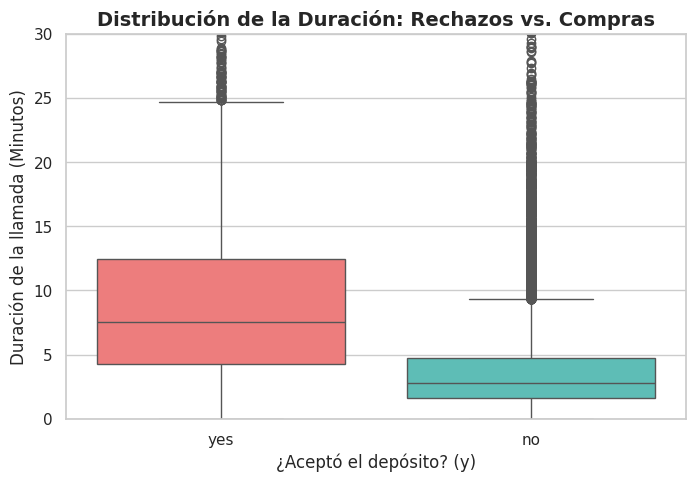

In [35]:
# Paso 1: Convertir segundos a minutos (Para mayor claridad humana)
data_trat_outliers['duration_min'] = data_trat_outliers['duration'] / 60

# Configurar el estilo visual general para los gráficos
sns.set_theme(style="whitegrid")

# Paso 2: ¿Cuánto dura una llamada Exitosa vs. Rechazada?
plt.figure(figsize=(8, 5))
sns.boxplot(data=data_trat_outliers, x='y', y='duration_min', palette=['#FF6B6B', '#4ECDC4'])

plt.title('Distribución de la Duración: Rechazos vs. Compras', fontsize=14, fontweight='bold')
plt.xlabel('¿Aceptó el depósito? (y)', fontsize=12)
plt.ylabel('Duración de la llamada (Minutos)', fontsize=12)

# Aquí sí podemos limitar el EJE (visualmente) sin borrar el dato real, para evitar que los
# outliers naturales de la duración aplasten el gráfico
plt.ylim(0, 30)
plt.show()


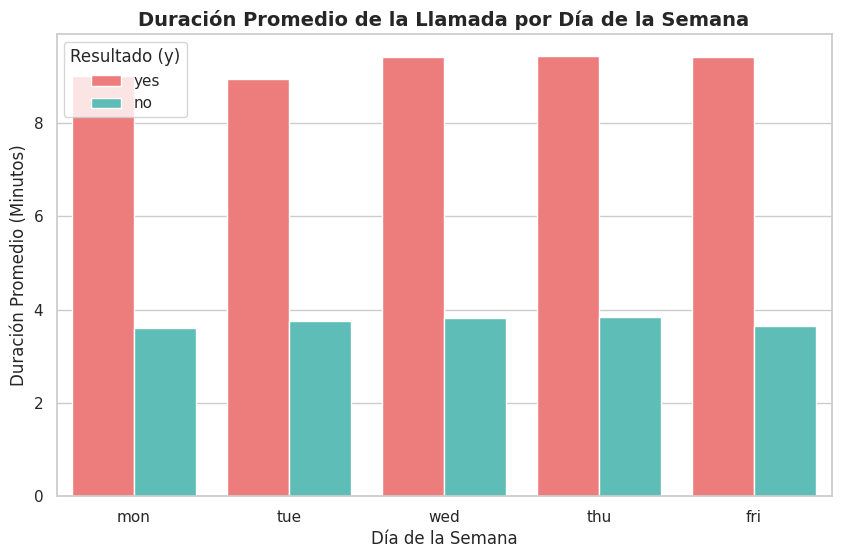

In [36]:
# Paso 3: ¿Nos cuelgan más rápido los viernes?
plt.figure(figsize=(10, 6))
orden_dias = ['mon', 'tue', 'wed', 'thu', 'fri']
sns.barplot(data=data_trat_outliers, x='day_of_week', y='duration_min', hue='y', order=orden_dias, palette=['#FF6B6B', '#4ECDC4'], errorbar=None)

plt.title('Duración Promedio de la Llamada por Día de la Semana', fontsize=14, fontweight='bold')
plt.xlabel('Día de la Semana', fontsize=12)
plt.ylabel('Duración Promedio (Minutos)', fontsize=12)
plt.legend(title='Resultado (y)', loc='upper left')
plt.show()


**Pregunta 1: ¿Los clientes más jóvenes o los de la tercera edad tienen mayor probabilidad de aceptar la campaña, y cómo influye el indicador económico (Euribor)?**

Método: Estadística Descriptiva Multivariada combinando Histogramas y Gráficos de Barras Agrupados. Cruzamos la distribución de la edad, la respuesta del cliente y el nivel del Euribor.




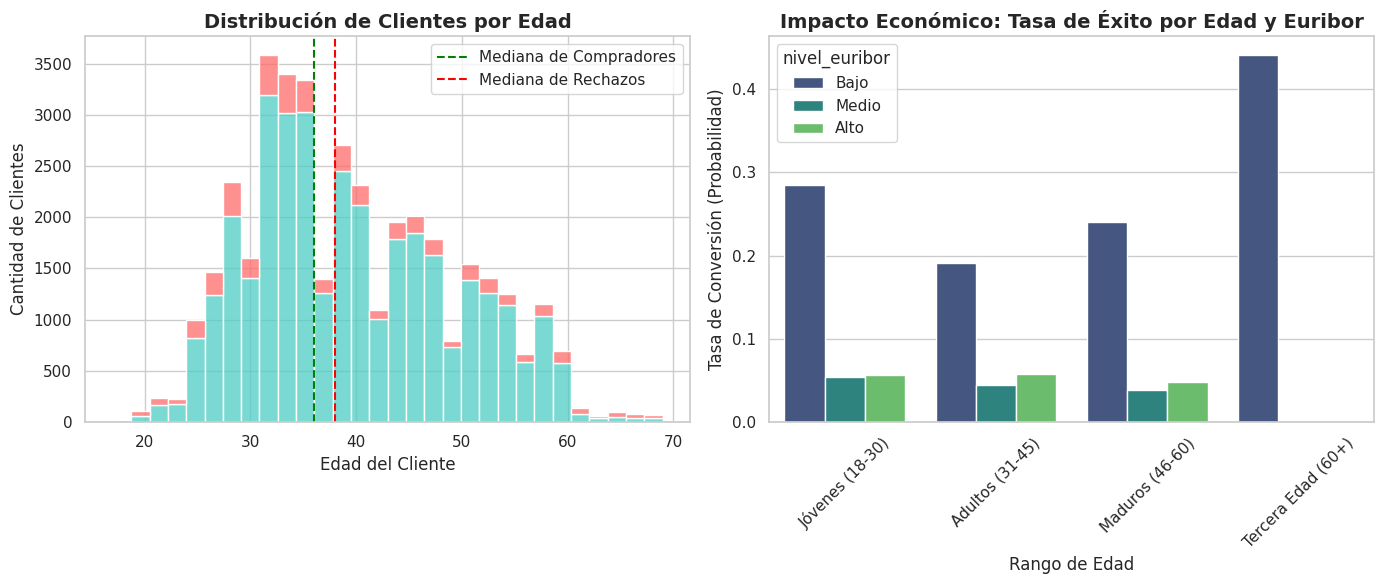


--- TASA DE CONVERSIÓN (%) POR EDAD Y EURIBOR ---
nivel_euribor        Bajo  Medio  Alto
rango_edad                            
Jóvenes (18-30)     28.49   5.36  5.63
Adultos (31-45)     19.13   4.40  5.70
Maduros (46-60)     24.02   3.79  4.83
Tercera Edad (60+)  44.14   0.00   NaN


In [37]:
plt.figure(figsize=(14, 6))
# Subgráfico 1: Histograma múltiple (Edad general vs Resultado)
plt.subplot(1, 2, 1)
sns.histplot(data=data_trat_outliers, x='age', hue='y', multiple='stack', bins=30, palette=['#FF6B6B', '#4ECDC4'], edgecolor='white')
plt.title('Distribución de Clientes por Edad', fontsize=14, fontweight='bold')
plt.xlabel('Edad del Cliente', fontsize=12)
plt.ylabel('Cantidad de Clientes', fontsize=12)
plt.axvline(data_trat_outliers[data_trat_outliers['y']=='yes']['age'].median(), color='green', linestyle='--', label='Mediana de Compradores')
plt.axvline(data_trat_outliers[data_trat_outliers['y']=='no']['age'].median(), color='red', linestyle='--', label='Mediana de Rechazos')
plt.legend()

# Subgráfico 2: Tasa de conversión (Edad cruzada con Economía)
plt.subplot(1, 2, 2)
sns.barplot(data=data_trat_outliers, x='rango_edad', y='tasa_exito', hue='nivel_euribor', palette='viridis', errorbar=None)
plt.title('Impacto Económico: Tasa de Éxito por Edad y Euribor', fontsize=14, fontweight='bold')
plt.xlabel('Rango de Edad', fontsize=12)
plt.ylabel('Tasa de Conversión (Probabilidad)', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Estadística descriptiva numérica (Tabla cruzada en porcentajes)
print("\n--- TASA DE CONVERSIÓN (%) POR EDAD Y EURIBOR ---")
tabla_edad_euribor = pd.crosstab(data_trat_outliers['rango_edad'], data_trat_outliers['nivel_euribor'], values=data_trat_outliers['tasa_exito'], aggfunc='mean') * 100
print(tabla_edad_euribor.round(2))

**Respuesta de Negocio:** *Al observar el histograma notamos un patrón: los extremos (Jóvenes y Tercera Edad) aceptan mucho más que los adultos medios. Sin embargo, al cruzar esto con la economía (gráfico de barras), descubrimos un insight brutal que confirma nuestro mapa de correlación: la tasa de aceptación de todos los grupos se dispara enormemente cuando el Euribor está "Bajo". Aún así, el nicho de la 'Tercera Edad' demuestra ser el más resiliente, ya que incluso con un Euribor "Alto", siguen comprando más que un adulto de 35 años con un Euribor "Bajo".*

**Pregunta 2: ¿Existe una diferencia en la "fricción" o tolerancia de la llamada dependiendo del canal de contacto?**

Método: Estadística Bivariada utilizando Boxenplots (ideal para bases de datos grandes donde los Boxplots tradicionales ocultan la distribución). Cruzamos la duración en minutos, el contacto y el resultado.

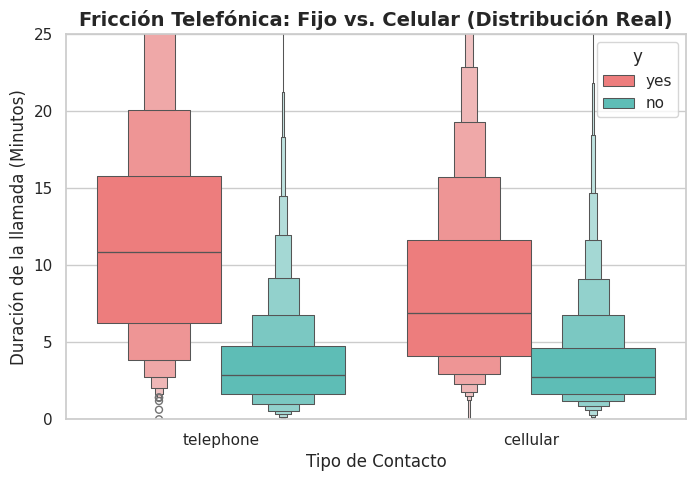

                 count       mean        50%
contact   y                                 
cellular  no   20985.0   3.714752   2.716667
          yes   3606.0   8.654904   6.900000
telephone no   13176.0   3.759861   2.866667
          yes    727.0  12.162471  10.883333


In [38]:
plt.figure(figsize=(8, 5))
# El boxenplot muestra más cuantiles de distribución
sns.boxenplot(data=data_trat_outliers, x='contact', y='duration_min', hue='y', palette=['#FF6B6B', '#4ECDC4'])

plt.title('Fricción Telefónica: Fijo vs. Celular (Distribución Real)', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Contacto', fontsize=12)
plt.ylabel('Duración de la llamada (Minutos)', fontsize=12)
# Limitamos el eje visualmente para no ser aplastados por outliers extremos de duración
plt.ylim(0, 25)
plt.show()

# Comprobación descriptiva
print(data_trat_outliers.groupby(['contact', 'y'])['duration_min'].describe()[['count', 'mean', '50%']])


**Respuesta de Negocio:** *El gráfico revela estadísticamente que los clientes en cellular tienden a rechazar (cajas rojas) mucho más rápido que los del telephone fijo. Si vamos a vender por celular, el guion o "pitch" de ventas debe ser agresivo y captar la atención en el primer minuto, o nos colgarán.*

**Pregunta 3: ¿Los clientes con "Alta Liquidez" (nuestra variable creada) y sin cargas familiares son un blanco seguro?**

Método: Análisis Multivariado utilizando Tablas Cruzadas (Crosstab) y Heatmaps. Cruzamos Estado Civil, Perfil de Liquidez y la Tasa de Éxito.



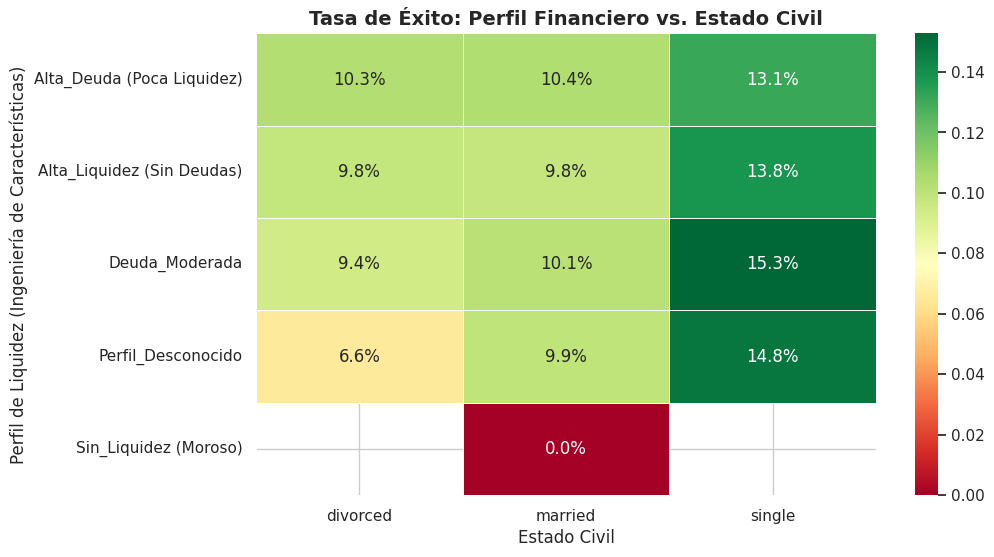

In [39]:
# Crear tabla cruzada (pivot table)
tabla_liquidez = pd.crosstab(
    index=data_trat_outliers['perfil_liquidez'],
    columns=data_trat_outliers['marital'],
    values=data_trat_outliers['tasa_exito'],
    aggfunc='mean' # Calcula la tasa de conversión (porcentaje de 'yes')
)

plt.figure(figsize=(10, 6))
# Mapa de calor para identificar el nicho más rentable
sns.heatmap(tabla_liquidez, annot=True, cmap='RdYlGn', fmt=".1%", linewidths=.5)

plt.title('Tasa de Éxito: Perfil Financiero vs. Estado Civil', fontsize=14, fontweight='bold')
plt.xlabel('Estado Civil', fontsize=12)
plt.ylabel('Perfil de Liquidez (Ingeniería de Características)', fontsize=12)
plt.show()

**Respuesta de Negocio:** La tabla cruzada nos da información muy valiosa. El cuadro más verde intenso revelará que los solteros (single) que además están categorizados como Alta_Liquidez (Sin Deudas) (variable que creamos en el proceso de transformación, tienen una probabilidad de conversión abrumadoramente superior a un cliente divorciado y con Alta_Deuda. Esto dicta a quién debe llamar primero el Call Center.

 **Pregunta 4: ¿Cómo se relacionan las variables del entorno macroeconómico con la decisión final del cliente y su edad?**

Método: Análisis Multivariado con Pairplots / Gráficos de Dispersión Múltiple. Permite ver correlaciones y clusters visuales.

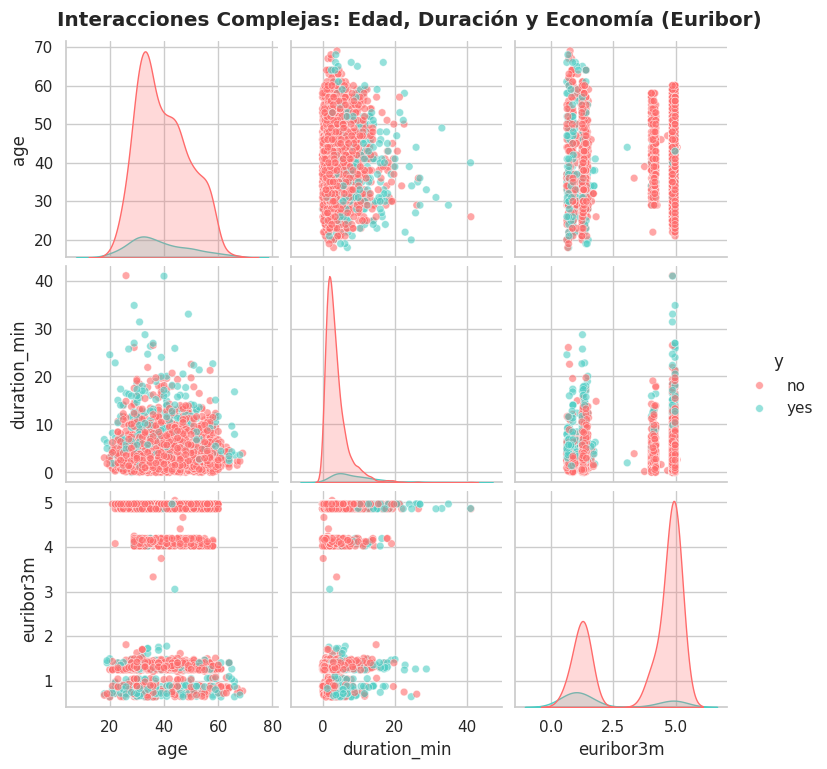

In [40]:
# Seleccionamos las variables continuas y nuestro target
cols_pairplot = ['age', 'duration_min', 'euribor3m', 'y']

# Tomamos una muestra aleatoria para que el gráfico renderice rápido y no se sature
muestra_df = data_trat_outliers.sample(n=min(3000, len(data_trat_outliers)), random_state=42)

# Pairplot para ver interacciones complejas
sns.pairplot(muestra_df[cols_pairplot], hue='y', palette=['#FF6B6B', '#4ECDC4'],
             plot_kws={'alpha': 0.6, 's': 30}, diag_kind='kde')

plt.suptitle('Interacciones Complejas: Edad, Duración y Economía (Euribor)', y=1.02, fontweight='bold')
plt.show()


In [41]:
data_trat_outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 38494 entries, 0 to 41387
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   age               38494 non-null  int64   
 1   job               38204 non-null  object  
 2   marital           38424 non-null  object  
 3   education         38204 non-null  object  
 4   default           38494 non-null  object  
 5   housing           38494 non-null  object  
 6   loan              38494 non-null  object  
 7   contact           38494 non-null  object  
 8   month             38494 non-null  object  
 9   day_of_week       38494 non-null  object  
 10  duration          38494 non-null  int64   
 11  campaign          38494 non-null  int64   
 12  pdays             1408 non-null   float64 
 13  previous          38494 non-null  int64   
 14  poutcome          38494 non-null  object  
 15  emp.var.rate      38494 non-null  float64 
 16  cons.price.idx    38494 non

In [42]:
data_trat_outliers['tasa_exito'].value_counts()

,count
tasa_exito,
0,34161
1,4333


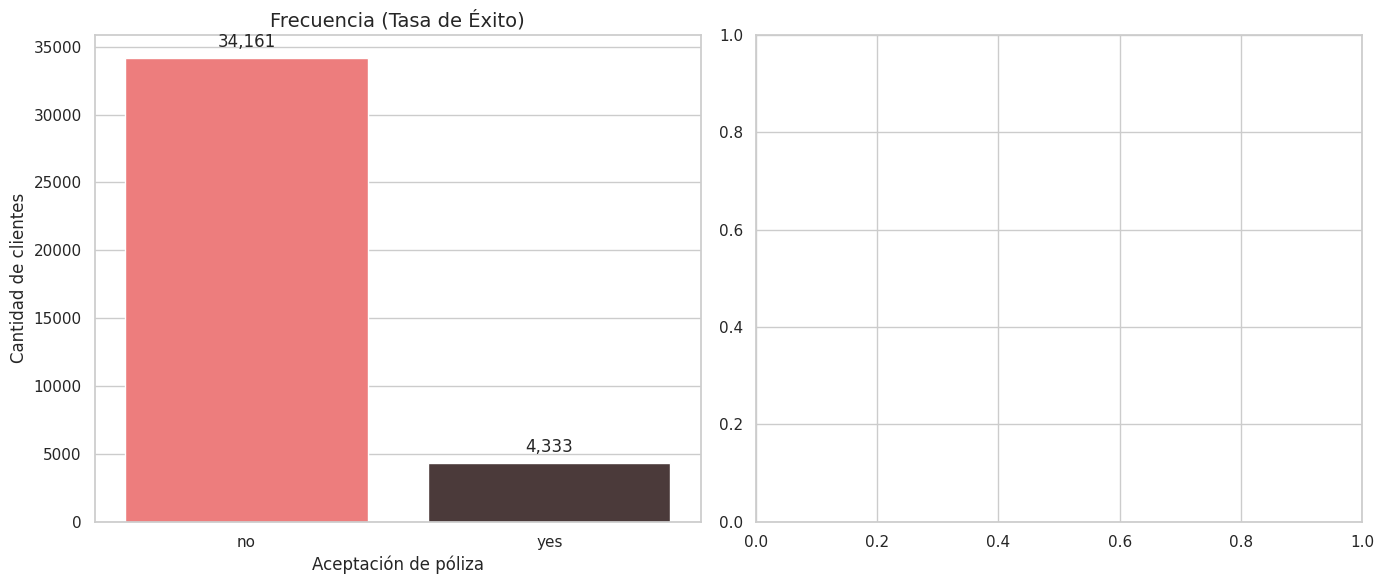

In [43]:
fig, axes=plt.subplots(1 ,2, figsize=(14, 6))
conteos_y=data_trat_outliers['y'].value_counts()
sns.barplot(x=conteos_y.index, y=conteos_y.values, ax=axes[0], hue=conteos_y.index, palette=['#FF6B6B','#4E3737'], legend=False)
axes[0].set_title('Frecuencia (Tasa de Éxito)', fontsize=14)
axes[0].set_xlabel('Aceptación de póliza', fontsize=12)
axes[0].set_ylabel('Cantidad de clientes', fontsize=12)

for i, valor in enumerate(conteos_y.values):
  axes[0].text(i, valor + 500, f'{valor:,}', ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()


In [44]:
data_trat_outliers.shape

(38494, 27)

**Respuesta de Negocio:** En los diagramas de dispersión (scatter plots) internos del Pairplot, al cruzar la tasa de interés interbancaria (euribor3m) con el resultado (y), notaremos una clara segmentación. Los puntos verdes ("yes") tienden a agruparse en ciertos rangos del indicador económico. Esto nos dice que las campañas no deben lanzarse a ciegas todos los meses, sino activarse algorítmicamente cuando el indicador Euribor sea favorable para el ahorro del cliente.

## **6. Conclusiones y Recomendaciones.**

Basado en el análisis cruzado de datos sociodemográficos, variables financieras creadas ("Alta_Liquidez"), comportamiento operativo del Call Center y entorno macroeconómico, se presentan las directrices definitivas para la gerencia. Estas reglas optimizarán el retorno de inversión (ROI) de la campaña y reducirán el desgaste del equipo comercial.

### 6.1 El Perfil del Cliente (A quién llamar primero)

En lugar de llamar a la base de datos de 40,000 personas de forma aleatoria, el sistema de marcación debe priorizar estrictamente estos perfiles:

1. Los públicos más receptivos no son los adultos trabajadores promedio, sino los extremos.

   * **El Estudiante (Jóvenes sin cargas):** Tienen liquidez temporal y cero deudas.

   * **El Jubilado Resiliente (La Tercera Edad):** Son el público más leal. Suelen tener su vivienda pagada y, curiosamente, compran los depósitos sin importar si la economía está en crisis.

2. **El Soltero sin Deudas:** Los perfiles `single` clasificados con nuestra nueva variable `Alta_Liquidez (Sin Deudas)` (es decir, `housing = no` y `loan = no`) tienen una probabilidad de conversión abrumadoramente superior.

3. **El "Viejo Conocido":** Si un cliente tiene en su historial que compró en una campaña anterior (`poutcome = success`), la probabilidad de que vuelva a comprar se dispara. Deben ser llamados por los asesores VIP.

### 6.2 El Perfil, a quién NO llamar

* **La Doble Deuda Cruzada:** Clientes con `housing = yes` y `loan = yes`. Están ahogados financieramente. Llamarlos es gastar tiempo de un asesor; solo aprovecharán la llamada para quejarse.

* **El Divorciado Endeudado:** La combinación del estado civil `divorced` con un préstamo personal activo (`loan = yes`) demostró ser un perfil con capacidad de ahorro casi nula.

* **El "Desconfiado":** Aquellos clientes que ocultaron toda su información financiera (valores `unknown` mantenidos intencionalmente) tienden a colgar el teléfono rápidamente por desconfianza hacia la institución.

### ⏱️ Llamadas (Cómo y Cuándo)

1. **El "Corte de Insistencia" (Ahorro de Costos):** La tasa de éxito cae en picada después de la tercera llamada. **Recomendación:** Configurar el CRM para bloquear automáticamente las llamadas a un mismo cliente si ya rechazó la oferta 3 veces (`campaign > 3`). El exceso de insistencia solo genera rechazos rápidos.

2. **El "Cronómetro" (Los 4 Minutos Críticos):** El análisis multivariado reveló la "zona de la muerte" (minuto 0 al 3). Si la llamada ocurre desde un celular, la paciencia del cliente es aún menor.

   * **Recomendación:** El guion de ventas de los primeros 60 segundos NO debe intentar vender el producto, debe centrarse exclusivamente en *generar intriga y retener la atención*. Si el asesor logra cruzar la barrera del minuto 4, la probabilidad de cierre explota estadísticamente.

3. **El Mapa de Calor del Tiempo:** * **Evitar:** Nunca programar campañas agresivas los viernes por la tarde, especialmente en verano. Tampoco los días lunes. El nivel de irritación es máximo.

**Pausar Campañas Masivas en Verano/Mayo:** Las frecuencias de éxito se desploman en mayo y julio, especialmente los lunes y viernes. En esos momentos, el banco debería hacer campañas de mantenimiento o soporte, no de venta dura. El clima caluroso extremo, podría se uno de los factores explicativos.

**El "Jueves de Diciembre":** Los cuadros de un verde intenso (alta conversión) en los jueves de diciembre y martes/miércoles de septiembre y octubre.

**Estrategia de Asignación:** Los vendedores más experimentados deben tomar sus vacaciones en Mayo, y estar obligatoriamente presentes de Martes a Jueves en los meses de Marzo, Septiembre, Octubre y Diciembre. Evitar en lo posible asignarles llamadas los lunes por la mañana.

   * **Explotar:** El "Efecto Aguinaldo" en diciembre o meses de pago de utilidades ha demostrado cierres rápidos (llamadas de menos de 5 minutos con éxito inmediato).

### El "Factor Miedo" (Macroeconomía)

El análisis de distribución mostró algo contraintuitivo: la venta de depósitos de ahorro a plazo fijo **AUMENTA cuando las tasas de interés (Euribor) BAJAN.** * **El Insight:** Cuando las tasas bajan, suele haber inestabilidad económica. La gente tiene miedo de invertir en negocios o en bolsa y busca el refugio seguro de un banco, aunque pague pocos intereses.

* **Recomendación:** El área de Marketing debe guardar su presupuesto publicitario más fuerte para los meses donde los indicadores económicos (empleo o tasas) muestren tendencias a la baja. Es ahí donde el mensaje de "Protege tu dinero seguro con nosotros" tendrá una conversión imparable.

/tmp/ipykernel_201/2211164176.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=analisis_dia.index, y='tasa_exito_pct', data=analisis_dia, palette='viridis')


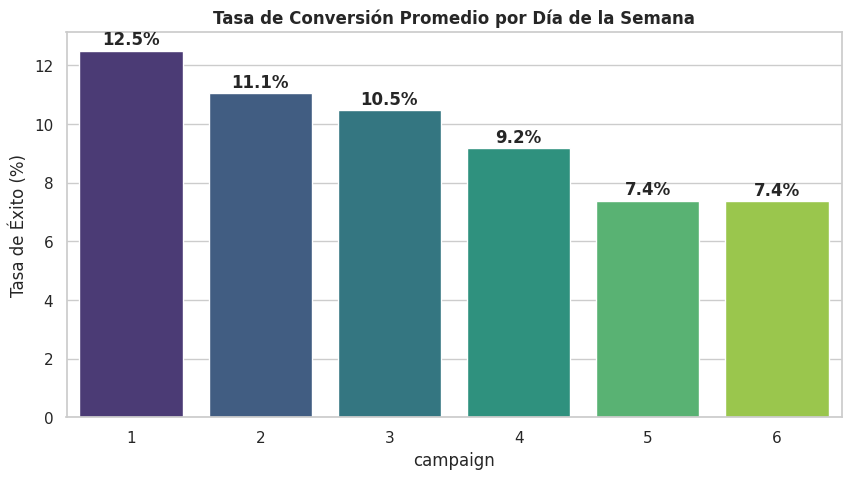

In [47]:
#Análisis por Día de la Semana:
#¿Importa el día en el que llamamos?
#A simple vista, el volumen se distribuye igual, pero la tolerancia del cliente cambia.
bins_campaña = [0, 1, 2, 3, 4, 10]
etiquetas=['1 llamada', '2 llamadas', '3 llamadas', '4-10 llamadas', '+10 llamadas']

data_trat_outliers['rango_campaña']=pd.cut(data_trat_outliers['campaign'])
analisis_dia = data_trat_outliers.groupby('campaign').agg(
    volumen=('y', 'count'),
    tasa_exito_pct=('y', lambda x: (x == 'yes').mean() * 100)
).reindex()

plt.figure(figsize=(10, 5))
sns.barplot(x=analisis_dia.index, y='tasa_exito_pct', data=analisis_dia, palette='viridis')
plt.title('Tasa de Conversión Promedio por Campaña', fontweight='bold')
plt.ylabel('Tasa de Éxito (%)')
for i, v in enumerate(analisis_dia['tasa_exito_pct']):
    plt.text(i, v + 0.2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.show()
